# Practical Lab — Local AI with Ollama
**Running and Developing Local AI Applications** · PHD Student 

**Prerequisites:** Python 3.10+, basic Python, basic understanding of APIs, 8–16 GB RAM (NVIDIA GPU optional).

**Technologies:** Ollama · Python · REST API · `requests` · (optional) Open WebUI · a local LLM (Qwen, Gemma, Llama…)

> Ollama exposes a local HTTP service on `localhost:11434`, so the same model can be used from the terminal, Python, or any other software.

### How to use this notebook
- Run cells top to bottom. Cells starting with `!` run shell commands.
- Change `MODEL` / `MODEL2` below if the model names differ on your installation.
- Fill in the **✍️ Your answer** cells — they feed your final report.

## Part 1 — Understanding Local AI

**Cloud AI**
```
Python App → Internet → Cloud API → LLM
```
**Local AI**
```
Python App → localhost:11434 → Ollama → Local LLM → GPU / CPU
```
Advantages to investigate: **privacy**, **offline operation**, **no per-token cost**.
Trade-off: local models may be **less capable or slower** than frontier cloud models, depending on hardware and model size.

## Part 2 — Installing Ollama
### Exercise 1 — Verify the environment

In [1]:
import sys, platform
print("Python  :", sys.version)
print("System  :", platform.system(), platform.release())
assert sys.version_info >= (3, 10), "Python 3.10+ required"

Python  : 3.11.17 (main, Oct  1 2026, 20:17:42) [GCC 14.3.0]
System  : Linux 7.0.0-38-generic


In [2]:
!pip --version

pip 26.2.2 from /home/passenger/miniconda3/envs/nvidia_phd/lib/python3.11/site-packages/pip (python 3.11)


### Exercise 2 — Install Ollama
Download the installer for your OS from <https://ollama.com/download> (Linux: `curl -fsSL https://ollama.com/install.sh | sh`). Then verify:

In [3]:
!ollama --version

]11;?\ollama version is 0.40.11


Make sure the Ollama service is running (the desktop app starts it automatically; otherwise run `ollama serve` in a separate terminal).

In [1]:
import requests

OLLAMA = "http://localhost:11434"

try:
    r = requests.get(OLLAMA, timeout=3)
    print("✅ Ollama server reachable:", r.text)
except requests.exceptions.ConnectionError:
    print("❌ Ollama is not running. Start it with `ollama serve` in a terminal.")

✅ Ollama server reachable: Ollama is running


## Part 3 — Your First Local LLM
### Exercise 3 — Download a model
If the exact name differs on your installation, pick a small instruct/chat model suited to your hardware.

In [2]:
# Models used throughout the lab — edit if needed
MODEL  = "qwen3.5:0.8b"   # Model 1
MODEL2 = "gemma3:1b"    # Model 2 (used in the comparison parts)

In [7]:
!ollama pull {MODEL}

]11;?\pulling manifest ⠋ pulling manifest ⠙ pulling manifest ⠹ pulling manifest ⠸ pulling manifest ⠼ pulling manifest ⠴ pulling manifest ⠦ pulling manifest ⠧ pulling manifest ⠇ pulling manifest ⠏ pulling manifest ⠋ pulling manifest ⠙ pulling manifest ⠹ pulling manifest ⠸ pulling manifest ⠼ pulling manifest ⠴ pulling manifest ⠦ pulling manifest ⠧ pulling manifest ⠇ pulling manifest ⠏ pulling manifest ⠋ pulling manifest ⠙ pulling manifest ⠹ pulling manifest ⠸ pulling manifest ⠼ pulling manifest ⠴ pulling manifest ⠦ pulling manifest ⠧ pulling manifest ⠇ pulling manifest ⠏ pulling manifest ⠋ pulling manifest ⠙ pulling manifest ⠹ pulling manifest ⠸ pulling manifest ⠼ pulling manifest ⠴ pulling manifest ⠦ pulling manifest ⠧ pulling manifest ⠇ pulling manifest ⠏ pulling manifest 
pulling 5ba2eb9bf28c:   0% ▕                  ▏ 664 KB/207 MB                  pulling manifest 
pulling 5ba2eb9bf28c:   1% ▕                  ▏ 1.3 MB/207 MB                  pulling manifest 
pulling 5ba2eb9bf28c

In [8]:
!ollama list

]11;?\NAME            ID              SIZE      MODIFIED       
qwen3.5:0.8b    de63045f2975    1.3 GB    12 seconds ago    


### Exercise 4 — Run the model
In the terminal you would use `ollama run qwen3.5`. Here we do the same thing through the API with a helper function.

In [3]:
import time, json

def generate(prompt, model=None, system=None, fmt=None, images=None, options=None, think=None):
    """Call Ollama /api/generate (non-streaming) and return the full JSON dict
    plus the measured wall-clock time under the key 'wall_s'."""
    payload = {"model": model or MODEL, "prompt": prompt, "stream": False}
    if system:  payload["system"] = system
    if fmt:     payload["format"] = fmt          # "json" or a JSON schema
    if images:  payload["images"] = images       # list of base64 strings
    if options: payload["options"] = options
    if think is not None: payload["think"] = think  # False disables 'thinking' on reasoning models
    t0 = time.perf_counter()
    r = requests.post(f"{OLLAMA}/api/generate", json=payload, timeout=600)
    r.raise_for_status()
    out = r.json()
    out["wall_s"] = time.perf_counter() - t0
    return out

def ask(prompt, **kw):
    """Shortcut: return only the text, and print timing."""
    out = generate(prompt, **kw)
    print(f"[{out['wall_s']:.1f}s]")
    return out["response"]

In [11]:
import textwrap

for p in [
    "Explain what artificial intelligence is in five sentences.",
    "Explain artificial intelligence to a 10-year-old child.",
    "Explain artificial intelligence to a computer science professor.",
]:
    print("="*80, "\nPROMPT:", p, "\n", flush=True)
    answer = ask(p)
    print(textwrap.fill(answer, width=90), flush=True)

PROMPT: Explain what artificial intelligence is in five sentences. 

[157.9s]
Artificial intelligence refers to the creation of computers that mimic human intelligence
through complex algorithms and data processing systems designed to learn from experiences.
These systems enable machines to perform tasks like recognition, analysis, and automation
that would normally require significant human expertise or time. Common applications
include natural language processing for communication, image recognition in security, and
predictive modeling for market trends. Consequently, these tools significantly enhance
productivity within industries ranging from healthcare to finance by improving efficiency
and accuracy. Ultimately, this technology is transforming how we work together with
machines and allows us to solve issues that were previously impossible or slow to address
manually.
PROMPT: Explain artificial intelligence to a 10-year-old child. 

[119.1s]
Hello! 🧬 Let's talk about Artificial Int

### Questions
1. Did the model produce different answers? Why?
2. Is the model communicating with a cloud API?
3. Where is inference being performed?
4. What happens if the Internet connection is disabled?

> 💡 Try it: disable Wi-Fi / unplug Ethernet and re-run the cell above.

**✍️ Your answer:**

### 1. Did the model produce different answers? Why?
- Yes. The model adapted its vocabulary, level of detail, and explanations to the target audience specified in each prompt.

### 2. Is the model communicating with a cloud API?
- No. The model is accessed through Ollama's local API, without needing a cloud service for inference.

### 3. Where is inference being performed?
- Inference is performed locally on my computer, using My hardware (GPU, CPU, RAM), depending on available resources.

### 4. What happens if the Internet connection is disabled?
- The model will continue working normally because Ollama runs locally. Once the model is downloaded, an Internet connection is not required for inference.

## Part 4 — Experiment with Prompts
### Exercise 5 — Prompt engineering

In [15]:
prompt_a = """You are a university professor.

Explain the concept of a Directed Acyclic Graph (DAG).

Your answer must contain:
1. Definition
2. Example
3. Adjacency matrix
4. Real-world application
5. One Python example"""

print(ask(prompt_a))

[251.3s]
**1. Definition**
In computer science and graph theory, a **Directed Acyclic Graph (DAG)**—often termed a Directed Forest or simply a DAG—is a data structure that represents a collection of edges in the form of directed lines connecting nodes. This graph allows for the modeling of topological dependencies where an entity can only move in one direction without crossing another entity's boundary, and crucially, there are no cycles.

A key property distinguishing a DAG from an undirected graph is that it possesses **no loops**; while edges point from the first node to the second node, there must never exist a cycle back to the starting point (e.g., $A \to B$, $B \to C$, but not $C \to A$). In practical terms, this structure allows for efficient analysis of system dependencies, ensuring that data flow or task dependencies do not loop back upon themselves.

**2. Example**
To visualize the concept, consider a "Data Pipeline" workflow in software development. Here is a DAG where:

* 

In [19]:
prompt_b = """You are a university professor.

Explain DAGs to a first-year computer science student.

Use simple language and one concrete example."""

print(ask(prompt_b), flush=True)

[219.8s]
Good morning! Welcome to my class, everyone. Today we are diving deep into one of the foundational concepts in computer science. While you’ve probably heard about "Graphs" before when discussing how computers process information or store data, there is a very specific type of graph that I want to talk to you about today: Directed Acyclic Graphs (or DAGs).

Imagine thinking of a complex city plan for the next year's school project. You might look at it like a road network with lots of intersections and highways. But if you look closely, there are some roads that loop back on themselves or branch into a new highway without a clear path to close out the loop. That would be a cycle.

In a DAG, the graph is simply a network where **there are no cycles**. This means you can always find a clear path from every node (a point on the road) to another node in the system, and no matter how long the journey is, it never loops back on itself without passing through a previous station.

In o

### Questions
Compare the two answers. Explain the role of: **role · context · constraints · output format · specificity**.

**✍️ Your answer:**

- **Role:** Both prompts assign the same role (university professor), so the model adopts a teaching style.

- **Context:** Prompt B specifies a first-year computer science student, resulting in simpler language. Prompt A does not specify the audience's level.

- **Constraints:** Prompt A requires five specific elements (definition, example, adjacency matrix, application, and Python code). Prompt B only requires simple language and one example.

- **Output format:** Prompt A produces a structured answer with numbered sections. Prompt B produces a more conversational explanation.

- **Specificity:** Prompt A is more detailed and specific, while Prompt B is more flexible and focused on beginners.

**Conclusion:** Prompt A produces a more technical and structured response, while Prompt B produces a simpler explanation. However, both answers contain inaccuracies, showing that more specific prompts do not necessarily guarantee correct results.

## Part 5 — Model Management
### Exercise 6 — List, show, and monitor models

In [20]:
!ollama list

]11;?\NAME            ID              SIZE      MODIFIED          
qwen3.5:0.8b    de63045f2975    1.3 GB    About an hour ago    


In [21]:
!ollama show {MODEL}

]11;?\  Model
    architecture        qwen35             
    parameters          752.39M            
    context length      262144             
    embedding length    1024               
    quantization        Q8_0               
    requires            0.30.0             
    renderer            qwen3.5            
    parser              qwen3.5            
    template source     renderer_parser    

  Capabilities
    completion     
    vision         
    tools          
    thinking       
        levels     false, true    
        default    true           

  Projector
    architecture        clip       
    parameters          100.59M    
    embedding length    768        
    dimensions          1024       

  Parameters
    draft_num_predict    2       
    presence_penalty     1.5     
    temperature          1       
    top_k                20      
    top_p                0.95    

  License
    Apache License               
    Version 2.0, January 2004    
  

In [22]:
!ollama ps

]11;?\NAME    ID    SIZE    PROCESSOR    CONTEXT    RUNNER    UNTIL 


The same information is available from the REST API (`/api/tags`, `/api/show`, `/api/ps`):

In [24]:
import pandas as pd

def downloaded_models():
    tags = requests.get(f"{OLLAMA}/api/tags").json()["models"]
    return pd.DataFrame([{
        "name": m["name"],
        "size_GB": round(m["size"]/1e9, 2),
        "family": m["details"].get("family"),
        "params": m["details"].get("parameter_size"),
        "quantization": m["details"].get("quantization_level"),
    } for m in tags])

def loaded_models():
    ps = requests.get(f"{OLLAMA}/api/ps").json()["models"]
    return pd.DataFrame([{
        "name": m["name"],
        "size_GB": round(m["size"]/1e9, 2),
        "in_VRAM_GB": round(m.get("size_vram", 0)/1e9, 2),
        "expires_at": m.get("expires_at"),
    } for m in ps])

print("Downloaded:"); display(downloaded_models())
print("Currently loaded in memory:"); display(loaded_models())

Downloaded:


,name,size_GB,family,params,quantization
0,qwen3.5:0.8b,1.32,qwen35,752.39M,Q8_0


Currently loaded in memory:


""


### Questions
- What information do you get from `ollama list` vs `ollama ps`?
- What is the difference between a model that is **downloaded** and one that is **loaded**?

**✍️ Your answer:**

### 1. What information do you get from `ollama list` vs `ollama ps`?
- `ollama list` shows all downloaded models, including their names, IDs, sizes, and modification dates.
- `ollama ps` shows models currently loaded in memory, including their memory usage, processor (CPU/GPU), and expiration time.

### 2. What is the difference between a model that is downloaded and one that is loaded?
- **Downloaded:** The model is stored on my computer's disk and is available to use.
- **Loaded:** The model is loaded into RAM and/or GPU VRAM, ready to perform inference.

## Part 6 — Compare Two Local Models
Install a second model suited to your computer.

In [25]:
!ollama pull {MODEL2}
!ollama list

]11;?\pulling manifest ⠋ pulling manifest ⠙ pulling manifest ⠹ pulling manifest ⠸ pulling manifest ⠼ pulling manifest ⠴ pulling manifest ⠦ pulling manifest ⠧ pulling manifest ⠇ pulling manifest ⠏ pulling manifest ⠋ pulling manifest ⠙ pulling manifest ⠹ pulling manifest ⠸ pulling manifest ⠼ pulling manifest ⠴ pulling manifest ⠦ pulling manifest ⠧ pulling manifest ⠇ pulling manifest ⠏ pulling manifest ⠋ pulling manifest ⠙ pulling manifest ⠹ pulling manifest ⠸ pulling manifest ⠼ pulling manifest ⠴ pulling manifest ⠦ pulling manifest ⠧ pulling manifest ⠇ pulling manifest 
pulling 2f8c3d137f24:   0% ▕                  ▏ 168 KB/806 MB                  pulling manifest 
pulling 2f8c3d137f24:   0% ▕                  ▏ 2.9 MB/806 MB                  pulling manifest 
pulling 2f8c3d137f24:   1% ▕                  ▏ 7.3 MB/806 MB                  pulling manifest 
pulling 2f8c3d137f24:   1% ▕                  ▏ 9.5 MB/806 MB                  pulling manifest 
pulling 2f8c3d137f24:   2% ▕       

### Exercise 7 — Same prompt, different models

In [27]:
prime_prompt = """Write a Python function that determines whether a number is prime.

Requirements:
- Python
- Type hints
- Docstring
- Explain the algorithm
- Give its time complexity"""

results = {}
for m in (MODEL, MODEL2):
    print("="*80, f"\nMODEL: {m}\n", flush=True)
    out = generate(prime_prompt, model=m)
    results[m] = out
    print(out["response"], flush=True)
    print(f"\n⏱ {out['wall_s']:.1f}s", flush=True)

MODEL: qwen3.5:0.8b

Here's a complete and well-structured Python function that checks whether a given number is prime using an optimized and efficient algorithm.

```python
"""
A Python function to determine if a number is prime.

This module defines helper functions for checking primality and provides 
a robust implementation suitable for production use in competitive programming, 
algorithm implementations, or any scenario requiring reliable primality testing.

Author: Example Implementation
Date: 2024-11-15
"""


def is_prime(number):
    """
    Checks whether a given integer 'number' is a prime number.

    Parameters:
        number (int): The integer to check for primality.

    Returns:
        bool: True if 'number' is prime, False otherwise.

    Raises:
        ValueError: If 'number' is not an integer or 0.
        TypeError: If 'number' is not a string or numeric type.
    """
    if not isinstance(number, (int, float)):
        raise TypeError(f"Input must be an int or f

Now fill in your evaluation (scores out of 5) and see the table:

In [28]:
scores = {
    MODEL:  {"Response quality /5": 2, "Code correctness /5": 1},
    MODEL2: {"Response quality /5": 5, "Code correctness /5": 5},
}

table = pd.DataFrame([
    {"Model": m, "Response time (s)": round(results[m]["wall_s"], 1), **scores[m]}
    for m in (MODEL, MODEL2)
])
table

,Model,Response time (s),Response quality /5,Code correctness /5
0,qwen3.5:0.8b,76.2,2,1
1,gemma3:1b,50.4,5,5


**Tip — test the generated code:** copy the function the model wrote into a cell and check it.

In [32]:
# Qwen3.5:0.8b function
def is_prime_qwen(number):
    if not isinstance(number, (int, float)):
        raise TypeError("Input must be an int or float")

    if number <= 0:
        return False

    if number == 2:
        return True
    if number % 2 == 0:
        return False

    sqrt = int(number ** 0.5) + 1
    for i in range(3, sqrt + 1, 2):
        if number % i == 0:
            return False
    return True

# Gemma3:1b function
def is_prime_gemma(number: int) -> bool:
    if number <= 1:
        return False

    for i in range(2, int(number**0.5) + 1):
        if number % i == 0:
            return False

    return True

In [33]:
def is_prime_reference(n: int) -> bool:
    if n < 2: return False
    if n < 4: return True
    if n % 2 == 0: return False
    i = 3
    while i * i <= n:
        if n % i == 0: return False
        i += 2
    return True


for name, candidate in [
    ("Qwen3.5:0.8b", is_prime_qwen),
    ("Gemma3:1b", is_prime_gemma)
]:
    errors = [
        n for n in range(-5, 2000)
        if candidate(n) != is_prime_reference(n)
    ]

    print(f"{name}: {'✅ PASSED' if not errors else '❌ FAILED'}")
    print(f"Incorrect predictions: {len(errors)}")
    print(f"Examples: {errors[:10]}\n")

# Paste the model's function below as `candidate` and compare:
# candidate = is_prime
# assert all(candidate(n) == is_prime_reference(n) for n in range(-5, 2000)), "Incorrect!"
# print("✅ candidate matches the reference on 0..2000")

Qwen3.5:0.8b: ❌ FAILED
Incorrect predictions: 1
Examples: [1]

Gemma3:1b: ✅ PASSED
Incorrect predictions: 0
Examples: []



### Questions
Which model is faster? Which produces better code? Which uses more memory? Which would you choose for programming assistance? Is the largest model necessarily the best?

**✍️ Your answer:**

#### 1. Which model is faster?
- **Gemma3:1b** is faster, taking 50.4 seconds compared to 76.2 seconds for Qwen3.5:0.8b.

#### 2. Which produces better code?
- **Gemma3:1b** produces better code. It meets all requirements and passes all test cases, while Qwen3.5 makes mistakes.

#### 3. Which uses more memory?
- **Qwen3.5:0.8b** uses more GPU memory in my experiment (1,030 MiB), compared to Gemma3:1b (906 MiB), even though Gemma3 has more parameters. This shows that memory usage depends on model architecture and runtime configuration, not just model size.

#### 4. Which would you choose for programming assistance?
- I would choose **Gemma3:1b** because it generates more accurate code, follows instructions better, and responds faster in this experiment.

#### 5. Is the largest model necessarily the best?
- **No.** Larger models are not always better. Performance depends on training quality, architecture, and the task. A smaller model can outperform a larger one in specific situations.

## Part 7 — Using Local AI from Python
### Exercise 8 — Python + Ollama
Project structure:
```
local_ai_lab/
├── app.py
├── requirements.txt
└── README.md
```
Install `requests` (already available here):

In [ ]:
!pip install -q requests

In [34]:
import os
os.makedirs("local_ai_lab", exist_ok=True)

In [35]:
%%writefile local_ai_lab/app.py
import requests

url = "http://localhost:11434/api/generate"

data = {
    "model": "qwen3.5:0.8b",
    "prompt": "Explain recursion in Python.",
    "stream": False
}

response = requests.post(url, json=data)
result = response.json()
print(result["response"])

Writing local_ai_lab/app.py


In [36]:
%%writefile local_ai_lab/requirements.txt
requests

Writing local_ai_lab/requirements.txt


In [38]:
%%writefile ../local_ai_lab/README.md
# local_ai_lab
Minimal Python client for a local Ollama server.
Run: `python app.py`

Writing ../local_ai_lab/README.md


In [ ]:
!python local_ai_lab/app.py

**Architecture:** `Python → HTTP POST → localhost:11434 → Ollama → Local LLM → response → Python`

Below is the same call shown step by step, including the **metadata** Ollama returns:

In [39]:
out = generate("Explain recursion in Python.")
print(out["response"][:600], "...\n")
print({k: v for k, v in out.items() if k not in ("response", "context", "thinking")})

In Python, **recursion** is a fundamental concept for designing recursive functions. It's a method of writing functions that call themselves in order to solve complex problems.

## Basic Definition and Signature

Recursion is implemented by creating a function called `f` where:
- The function calls itself with an updated parameter value
- Each level builds on the previous one, moving from larger arguments down
- A **base case** must be reached for termination of recursion

### Recursive Function Signature:
```python
def f(n):  # Example signature
    return n + 1
```

## Key Features

1. **Rec ...

{'model': 'qwen3.5:0.8b', 'created_at': '2026-10-25T00:46:32.356344381Z', 'done': True, 'done_reason': 'stop', 'total_duration': 69941208103, 'load_duration': 9588143121, 'prompt_eval_count': 16, 'prompt_eval_cached_count': 0, 'prompt_eval_duration': 263646000, 'eval_count': 797, 'eval_duration': 60085191000, 'wall_s': 69.96250351799972}


## Part 8 — Build a Local AI Chatbot
### Exercise 9 — Interactive chatbot
`input()` works inside Jupyter (a prompt box appears). Type `exit` to stop.

In [7]:
URL = f"{OLLAMA}/api/generate"

def ask_ai(prompt):
    data = {"model": MODEL, "prompt": prompt, "stream": False}
    response = requests.post(URL, json=data)
    response.raise_for_status()
    return response.json()["response"]

def chat_loop_stateless():
    print("Local AI Assistant\nType 'exit' to stop.")
    while True:
        question = input("\nYou: ")
        if question.lower() == "exit":
            break
        print("\nAI:", ask_ai(question))

# chat_loop_stateless()   # <- uncomment to run

In [10]:
# Non-interactive test (works without typing):
for q in ["What is machine learning?", "Explain reinforcement learning."]:
    print("You:", q, flush=True); print("AI:", ask_ai(q)[:500], "...\n", flush=True)

You: What is machine learning?
AI: Machine learning (ML) is a subset of Artificial Intelligence that allows computers to learn from data without being explicitly programmed to do all tasks manually. At its core, it works by using algorithms or statistical methods to identify patterns and make decisions based on examples provided by humans or other systems.

### How Machine Learning Works
1.  **Data Preparation:** The process begins with a collection of labeled data (information known about the output of an input), such as images, ...

You: Explain reinforcement learning.
AI: **Reinforcement Learning (RL)** is the scientific field of developing a method of learning through trial and error within an environment where actions have both positive or negative consequences. It allows machines to learn how to solve tasks that are not easily programmed using traditional data-based methods.

In short, **it is about creating agents (machines) that learn how to act effectively by rewarding their b

## Part 9 — Add Conversation Memory
The previous app treats each question independently. We now send the **conversation history** with each request.

In [8]:
history = []

def ask_ai_memory(question):
    history.append(f"User: {question}")
    prompt = "\n".join(history) + "\nAssistant:"
    data = {"model": MODEL, "prompt": prompt, "stream": False}
    response = requests.post(URL, json=data)
    response.raise_for_status()
    answer = response.json()["response"]
    history.append(f"Assistant: {answer}")
    return answer

def chat_loop_memory():
    while True:
        question = input("\nYou: ")
        if question.lower() == "exit":
            break
        print("\nAI:", ask_ai_memory(question))

# chat_loop_memory()   # <- uncomment for interactive use

In [9]:
history.clear()
for q in ["My name is Ahmed.", "What is my name?"]:
    print("You:", q)
    print("AI :", ask_ai_memory(q), "\n", flush=True)

You: My name is Ahmed.
AI : Hello! It's great to meet you, Ahmed. How can I assist you today? 

You: What is my name?
AI : Ahmed, thank you for confirming! It's great to meet you. How can I assist you today? 



In [11]:
print("What the model actually received on the last call:\n" + "-"*50)
print("\n".join(history[:-1]) + "\nAssistant:")

What the model actually received on the last call:
--------------------------------------------------
User: My name is Ahmed.
Assistant: Hello! It's great to meet you, Ahmed. How can I assist you today?
User: What is my name?
Assistant:


### Question
Why does the model remember the name? Is the LLM itself remembering?

**✍️ Your answer:**

The model remembers the name because the Python history list stores previous messages and includes them in each new prompt. The LLM itself does not remember information between calls. Instead, it uses the conversation history provided in the prompt to understand the context and generate an appropriate response.

---
#### Better approach: the `/api/chat` endpoint
Ollama also has a chat endpoint taking structured `messages` (with `system` / `user` / `assistant` roles) and applying the model's own chat template.

In [12]:
def chat(messages, model=None, **kw):
    payload = {"model": model or MODEL, "messages": messages, "stream": False, **kw}
    r = requests.post(f"{OLLAMA}/api/chat", json=payload, timeout=600)
    r.raise_for_status()
    return r.json()

msgs = [{"role": "system", "content": "You are a concise assistant."},
        {"role": "user", "content": "My name is Ahmed."}]
reply = chat(msgs)["message"]
msgs.append(reply)
msgs.append({"role": "user", "content": "What is my name?"})
print(chat(msgs)["message"]["content"])

Hello! How can I help you today?


## Part 10 — Local AI for Software Engineering
### Exercise 10 — Code assistant

In [14]:
java_review = """You are a senior Java developer.

Review the following Java code:

public class Calculator {

    public int divide(int a, int b) {
        return a / b;
    }
}

Identify:
1. Potential problems
2. Runtime errors
3. Improvements
4. Corrected code"""

print(ask(java_review))

[170.9s]
# Java Calculator Class Review & Corrections

Below is a comprehensive analysis of the provided `Calculator` class, covering potential issues, runtime exceptions, performance optimizations, and corrected code for improved maintainability and robustness.

## 1. Potential Problems

| Issue | Description |
|-------|-------------|
| **No Input Validation** | No checks to ensure `a` and `b` are positive or non-zero integers. |
| **No Exception Handling** | No handling of edge cases (e.g., division by zero). |
| **Overflow Risk** | Standard integer types can overflow when multiplied/divided with very large numbers. |
| **Infinite Loops** | No protection against infinite recursion in complex scenarios. |

## 2. Runtime Errors

| Runtime Error | Cause | Solution |
|---------------|-------|----------|
| `NumberFormatException` | Input is not an integer type (e.g., string). | Validate inputs before use. |
| `ArithmeticException` | Division by zero (b = 0). | Throw exception with clear m

In [15]:
buggy = """You are a senior Java developer.

Find the bug in this code and explain how to fix it:

public class Student {

    private String name;
    private int age;

    public Student(String name) {
        this.name = name;
    }

    public void setAge(int age) {
        age = age;
    }

    public String getName() {
        return name;
    }
}"""

print(ask(buggy))

[247.8s]
I've reviewed your Java class and method, and I notice there's a small bug in the `setAge` method:

```java
public void setAge(int age) {
    age = age;  // This does nothing but silently assign itself - it's actually valid Java
}
```

### Is this a Bug?

**It is not a logic or syntax bug.** The code is syntactically correct and compiles without error, and the `age` variable is assigned correctly to the instance parameter. However, for clarity and proper handling in your class structure, here are some best practices and improvements:

### 1. **Use Proper Type Annotations**
You're currently using a generic constructor that takes a `String` instead of an `int`. Here's a corrected version that maintains backward compatibility:

```java
public class Student {
    private String name;
    private int age;

    public Student(String name) {
        this.name = name;
    }

    public void setAge(int age) {
        // Ensure the setter handles invalid values gracefully (e.g., check f

> ✅ Expected finding: `age = age;` assigns the parameter to itself (variable shadowing); it should be `this.age = age;`. Did your model find it? Is `age` also never initialized in the constructor?


**Answer:**

No, the model recognized `age = age;` but failed to fix it correctly. It should be `this.age = age;` because of variable shadowing. Also, `age` is not explicitly initialized in the constructor, so Java assigns it a default value of `0`.

## Part 11 — Structured Output
### Exercise 11
First, the naive approach: ask for "ONLY JSON" in the prompt.

In [16]:
json_prompt = """Analyze the following student:

Name: Ahmed
Age: 21
Grade: 15.5
Absences: 2

Return ONLY JSON with this structure:

{
  "name": "...",
  "age": 0,
  "grade": 0,
  "risk": "...",
  "recommendation": "..."
}"""

raw = ask(json_prompt, think=False)
print(raw)

[4.4s]
```json
{
  "name": "Ahmed",
  "age": 21,
  "grade": 15.5,
  "risk": "High",
  "recommendation": "Increased attendance and academic responsibilities required due to grade and absence metrics."
}
```


In [17]:
import re

def extract_json(text):
    """Robust parsing: strip ```json fences and grab the first {...} block."""
    text = re.sub(r"```(?:json)?", "", text).strip()
    m = re.search(r"\{.*\}", text, re.DOTALL)
    return json.loads(m.group(0))

try:
    print(extract_json(raw))
except Exception as e:
    print("❌ Could not parse:", e)

{'name': 'Ahmed', 'age': 21, 'grade': 15.5, 'risk': 'High', 'recommendation': 'Increased attendance and academic responsibilities required due to grade and absence metrics.'}


Better: use Ollama's **structured outputs** — pass a JSON Schema in `format` so the output is constrained to be valid.

In [18]:
schema = {
    "type": "object",
    "properties": {
        "name": {"type": "string"},
        "age": {"type": "integer"},
        "grade": {"type": "number"},
        "risk": {"type": "string", "enum": ["low", "medium", "high"]},
        "recommendation": {"type": "string"},
    },
    "required": ["name", "age", "grade", "risk", "recommendation"],
}

out = generate(json_prompt, fmt=schema, think=False)
student = json.loads(out["response"])
print(json.dumps(student, indent=2))
print("Type of grade:", type(student["grade"]))

{
  "name": "Ahmed",
  "age": 21,
  "grade": 15.5,
  "risk": "high",
  "recommendation": "Academic intervention and attendance improvement scheduled within the next week."
}
Type of grade: <class 'float'>


### Question
Why is structured output important when integrating an LLM into a software application?

**✍️ Your answer:**

Structured output is important because it ensures the LLM returns data in a consistent, predictable format such as JSON. This makes it easier for applications to parse, validate, and process responses automatically, reducing formatting errors and improving reliability when integrating LLMs into software systems.

## Part 12 — Local AI Document Assistant
Create `documents/course.txt`:

In [4]:
import os

In [21]:
os.makedirs("../documents", exist_ok=True)
with open("../documents/course.txt", "w", encoding="utf-8") as f:
    f.write("""Machine learning is a branch of artificial intelligence.

Supervised learning uses labelled data.

Unsupervised learning works with unlabelled data.

Reinforcement learning learns through interaction
with an environment using rewards and penalties.
""")

### Exercise 12 — Read the document and ask questions

In [22]:
with open("../documents/course.txt", "r", encoding="utf-8") as file:
    document = file.read()
print(document)

Machine learning is a branch of artificial intelligence.

Supervised learning uses labelled data.

Unsupervised learning works with unlabelled data.

Reinforcement learning learns through interaction
with an environment using rewards and penalties.



In [23]:
def ask_document(question, document):
    prompt = f"""
Answer the question using only the following document.

DOCUMENT:
{document}

QUESTION:
{question}

If the answer is not contained in the document,
say: "Information not available."
"""
    return ask(prompt, think=False)

print(ask_document("What is reinforcement learning?", document))
print()
print(ask_document("What is quantum computing?", document))

[1.6s]
Reinforcement learning is learned through interaction with an environment using rewards and penalties.

[4.5s]
Based on the document provided, I cannot find information regarding what quantum computing is. The text discusses machine learning, supervised and unsupervised learning, and reinforcement learning, but none of these topics or any related concepts about quantum computing are mentioned in it.

**Information not available.**


**Observe:** the second answer should be *"Information not available."* — the model is grounded in the supplied document instead of its own training data. Does your model respect the instruction every time?

**✍️ Your observation:**

The model correctly answered the first question using the document. For the second question, it recognized that the information was missing but did not follow the exact required format. Therefore, the model respects the document's content but does not always follow the output instructions precisely.

## Part 13 — Mini-RAG
We create four documents, then build a **local retriever** that picks the most relevant one for a question and feeds it to the LLM.

In [24]:
docs = {
"ai.txt": """Artificial intelligence (AI) is the field of computer science that builds systems able to perform tasks normally requiring human intelligence, such as reasoning, perception, language understanding and decision making. AI includes machine learning, expert systems, robotics and natural language processing.""",

"machine_learning.txt": """Machine learning is a branch of artificial intelligence. Supervised learning uses labelled data to learn a mapping from inputs to outputs (classification, regression). Unsupervised learning works with unlabelled data to discover structure such as clusters. Overfitting happens when a model memorises training data and generalises poorly.""",

"reinforcement_learning.txt": """Reinforcement learning learns through interaction with an environment using rewards and penalties. An agent observes a state, chooses an action, and receives a reward. The goal is to learn a policy that maximises the cumulative reward. Q-learning and policy gradients are common algorithms.""",

"deep_learning.txt": """Deep learning uses artificial neural networks with many layers to learn representations from large amounts of data. Convolutional neural networks are used for images, recurrent networks and transformers for sequences and language. Training deep networks usually requires GPUs.""",
}

for name, text in docs.items():
    with open(f"../documents/{name}", "w", encoding="utf-8") as f:
        f.write(text)
os.listdir("../documents")

['course.txt',
 'deep_learning.txt',
 'machine_learning.txt',
 'reinforcement_learning.txt',
 'ai.txt']

In [25]:
%%writefile ../local_ai_lab/rag.py
"""Mini-RAG: a tiny local retriever + prompt builder (keyword TF-IDF, no extra libraries)."""
import math, os, re
from collections import Counter

STOPWORDS = set("""a an the of to in on and or is are was were be by for with as at from that this
it its what which who how why when where do does did can could should would about into using use
learn learns through between such""".split())


def tokenize(text):
    return [w for w in re.findall(r"[a-zA-Z]+", text.lower()) if w not in STOPWORDS]


def load_documents(folder="../documents"):
    docs = {}
    for fn in sorted(os.listdir(folder)):
        if fn.endswith(".txt"):
            with open(os.path.join(folder, fn), encoding="utf-8") as f:
                docs[fn] = f.read()
    return docs


class Retriever:
    def __init__(self, docs):
        self.docs = docs
        self.tokens = {n: Counter(tokenize(t)) for n, t in docs.items()}
        df = Counter(w for c in self.tokens.values() for w in c)
        N = len(docs)
        self.idf = {w: math.log((N + 1) / (d + 0.5)) for w, d in df.items()}

    def score(self, question):
        q = tokenize(question)
        return {
            name: sum(self.idf.get(w, 0) * (1 + math.log(c[w])) for w in set(q) if c[w] > 0)
            for name, c in self.tokens.items()
        }

    def top(self, question, k=1, min_score=0.01):
        ranked = sorted(self.score(question).items(), key=lambda x: -x[1])
        return [(n, s) for n, s in ranked[:k] if s >= min_score]

    def context(self, question, k=1):
        hits = self.top(question, k)
        return hits, "\n\n".join(f"[{n}]\n{self.docs[n]}" for n, _ in hits)


def build_prompt(question, context):
    return f"""Answer the question using only the CONTEXT below.
If the answer is not contained in the context, say: "Information not available."

CONTEXT:
{context if context else '(no relevant document found)'}

QUESTION:
{question}
"""

Writing ../local_ai_lab/rag.py


In [27]:
import importlib
import sys

sys.path.insert(0, "../local_ai_lab")

import rag
importlib.reload(rag)

retriever = rag.Retriever(rag.load_documents("../documents"))

def rag_answer(question, k=1, model=None):
    hits, ctx = retriever.context(question, k)
    out = generate(rag.build_prompt(question, ctx), model=model, think=False)
    return hits, out["response"], out["wall_s"]

for q in ["What is reinforcement learning?",
          "Which hardware is needed to train neural networks with many layers?",
          "What is supervised learning?",
          "Who won the 2018 World Cup?"]:
    hits, ans, t = rag_answer(q)
    print(f"Q: {q}\n  retrieved: {hits}\n  A: {ans.strip()}\n  ({t:.1f}s)\n")

Q: What is reinforcement learning?
  retrieved: [('course.txt', 1.0831034956175303)]
  A: Reinforcement learning is a subset of machine learning where an agent (such as a robot or artificial intelligence program) interacts with a control environment, taking actions to achieve the goal of the task, and receiving a reward for each action based on that outcome.
  (14.5s)

Q: Which hardware is needed to train neural networks with many layers?
  retrieved: [('deep_learning.txt', 8.42789552798877)]
  A: Using only the context provided, it is not explicitly stated which specific hardware device (such as CPUs, GPUs, or ASICs) is strictly necessary for training networks with "many layers." The text mentions that "training deep networks usually requires GPUs" as a requirement for efficiency in data processing, but it does not specify that high-end computing power like thousands of cores or single-core performance is required simply because of the layer count.

Therefore, based solely on the cont

**Architecture**
```
Documents → Local Retriever → Relevant Context → Ollama → Local LLM → Answer
```
This is the fundamental idea behind **Retrieval-Augmented Generation (RAG)**.

#### Optional extension — semantic retrieval with embeddings
Keyword matching fails when the question uses different words than the document. Ollama can also compute embeddings locally (`ollama pull nomic-embed-text`).

In [5]:
EMBED_MODEL = "nomic-embed-text"

In [32]:
!ollama pull {EMBED_MODEL}      # <- uncomment once

]11;?\pulling manifest ⠋ pulling manifest ⠙ pulling manifest ⠹ pulling manifest ⠸ pulling manifest ⠼ pulling manifest ⠴ pulling manifest ⠦ pulling manifest ⠧ pulling manifest ⠇ pulling manifest ⠏ pulling manifest ⠋ pulling manifest ⠙ pulling manifest ⠹ pulling manifest ⠸ pulling manifest ⠼ pulling manifest ⠴ pulling manifest ⠦ pulling manifest ⠧ pulling manifest ⠇ pulling manifest ⠏ pulling manifest ⠋ pulling manifest ⠙ pulling manifest ⠹ pulling manifest ⠸ pulling manifest ⠼ pulling manifest ⠴ pulling manifest ⠦ pulling manifest ⠧ pulling manifest ⠇ pulling manifest ⠏ pulling manifest ⠋ pulling manifest ⠙ pulling manifest ⠹ pulling manifest ⠸ pulling manifest 
pulling 970aa74c0a90:   0% ▕                  ▏ 1.1 MB/274 MB                  pulling manifest 
pulling 970aa74c0a90:   1% ▕                  ▏ 3.3 MB/274 MB                  pulling manifest 
pulling 970aa74c0a90:   3% ▕                  ▏ 7.4 MB/274 MB                  pulling manifest 
pulling 970aa74c0a90:   4% ▕         

In [33]:
import numpy as np

def embed(texts):
    r = requests.post(f"{OLLAMA}/api/embed", json={"model": EMBED_MODEL, "input": texts})
    r.raise_for_status()
    return np.array(r.json()["embeddings"])

def semantic_top(question, docs, k=1):
    names = list(docs)
    D = embed([docs[n] for n in names]); q = embed([question])[0]
    sims = D @ q / (np.linalg.norm(D, axis=1) * np.linalg.norm(q))
    return sorted(zip(names, sims), key=lambda x: -x[1])[:k]

print(semantic_top("What hardware accelerates network training?", rag.load_documents("../documents"), k=2))

[('deep_learning.txt', np.float64(0.6378899700192129)), ('course.txt', np.float64(0.5333670734978316))]


## Part 14 — Local AI Vision *(optional)*
Requires a **multimodal** model, e.g. `ollama pull gemma3` (vision-capable variants), `llava`, `qwen2.5vl`, `llama3.2-vision`.

In [6]:
VISION_MODEL = MODEL   # change to a vision-capable model you have installed
IMAGE_PATH = "../imgs/cat.jpg"  # put an image next to the notebook

Based on an analysis of the image, here are the details requested:

**1. Main Objects:**
A single orange tabby kitten (likely a Miniature or English Persian) captured in a studio pose. It is seated upright with its body aligned forward, looking directly at the camera. Its fur is fluffy and orange with darker stripes on its body and tail tip.

**2. Environment:**
The background is a seamless, solid white surface, indicating a professional studio setting (like a photography set). There is no other furniture or context visible.

**3. Text Visible in the Image:**
There is a small, faint watermark located in the bottom right corner of the image. It appears to be an "@", likely serving as a handle for social media or part of a copyright/sponsorship logo. No text is visible on the kitten itself.

**4. Possible Interpretation:**
This appears to be a commercial photography shot, likely intended for e-commerce (selling cat products like grooming kits) or social media marketing (Instagram/TikTok 

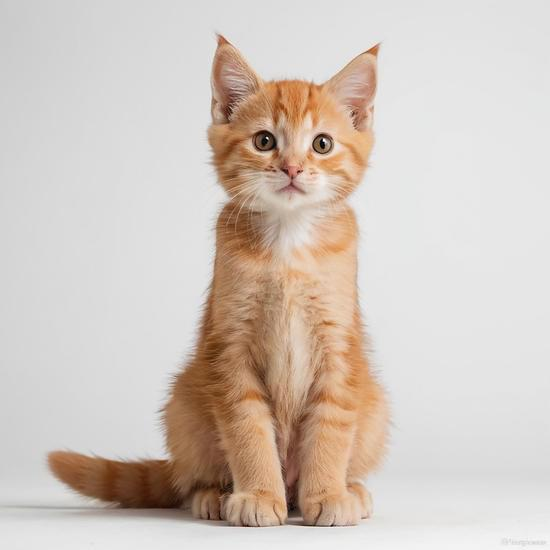

In [37]:
import base64

def analyze_image(path, model):
    with open(path, "rb") as f:
        b64 = base64.b64encode(f.read()).decode()
    prompt = """Analyze this image.

Identify:
1. Main objects
2. Environment
3. Text visible in the image
4. Possible interpretation"""
    return generate(prompt, model=model, images=[b64])

if os.path.exists(IMAGE_PATH):
    out = analyze_image(IMAGE_PATH, VISION_MODEL)
    print(out["response"], f"\n⏱ {out['wall_s']:.1f}s")
    from IPython.display import Image, display
    display(Image(IMAGE_PATH, width=400))
else:
    print(f"⚠️ Put an image named '{IMAGE_PATH}' next to this notebook, then re-run.")

### Questions
- Difference between an LLM and a multimodal model?
- What additional information does the vision model receive?
- Which applications could use local vision AI? *(document analysis, OCR, industrial inspection, education, medical-image preprocessing, surveillance analysis…)*

**✍️ Your answer:**

#### 1. Difference between an LLM and a multimodal model?
- An LLM primarily processes and generates text, while a multimodal model can understand different types of data, such as text, images, and audio, depending on its capabilities.

#### 2. What additional information does the vision model receive?
- The vision model receives image data in addition to the text prompt. This allows it to identify objects, understand visual environments, and recognize visible text.

#### 3. Which applications could use local vision AI?
- Local vision AI can be used for document analysis, OCR, industrial quality inspection, education, medical image analysis, and security monitoring. Running locally also improves data privacy because images do not need to be sent to cloud services.

## Part 15 — Build a Local AI Web Application
Structure:
```
local-ai-web/
├── app.py
├── templates/index.html
└── static/
```

In [ ]:
!pip install -q flask requests

In [38]:
os.makedirs("../local-ai-web/templates", exist_ok=True)
os.makedirs("../local-ai-web/static", exist_ok=True)

In [39]:
%%writefile ../local-ai-web/app.py
from flask import Flask, render_template, request
import requests

app = Flask(__name__)

OLLAMA_URL = "http://localhost:11434/api/generate"
MODEL = "qwen3.5"


@app.route("/", methods=["GET", "POST"])
def index():
    answer = ""

    if request.method == "POST":
        question = request.form["question"]
        data = {"model": MODEL, "prompt": question, "stream": False}
        response = requests.post(OLLAMA_URL, json=data)
        answer = response.json()["response"]

    return render_template("index.html", answer=answer)


if __name__ == "__main__":
    app.run(debug=True)

Writing ../local-ai-web/app.py


In [40]:
%%writefile ../local-ai-web/templates/index.html
<!DOCTYPE html>
<html>
<head>
    <title>Local AI Assistant</title>
</head>
<body>

<h1>Local AI Assistant</h1>

<form method="POST">
    <textarea name="question" rows="8" cols="70" placeholder="Ask your local AI..."></textarea>
    <br><br>
    <button type="submit">Ask</button>
</form>

{% if answer %}
<h2>Response</h2>
<pre>{{ answer }}</pre>
{% endif %}

</body>
</html>

Writing ../local-ai-web/templates/index.html


Run it **from a terminal** (not inside the notebook):
```bash
cd local-ai-web
python app.py
```
then open <http://127.0.0.1:5000>. 🎉 You now have a complete local AI web application.

*(📸 Take a screenshot for your report: `screenshots/06_webapp.png`.)*

## Part 16 — Performance Benchmark
We measure: response time, model size, tokens generated, tokens/second, RAM and GPU consumption.

Ollama returns precise counters: `eval_count` (generated tokens), `eval_duration` (ns), `prompt_eval_count`, `load_duration`.

In [ ]:
!pip install -q psutil

In [41]:
%%writefile ../local_ai_lab/benchmark.py
"""Benchmark local Ollama models on the same prompt."""
import time, requests, psutil, pandas as pd

OLLAMA = "http://localhost:11434"
PROMPT = "Write a 500-word explanation of reinforcement learning."


def unload(model):
    requests.post(f"{OLLAMA}/api/generate", json={"model": model, "keep_alive": 0})
    time.sleep(2)


def loaded_info(model):
    for m in requests.get(f"{OLLAMA}/api/ps").json()["models"]:
        if m["name"].startswith(model.split(":")[0]):
            return m["size"] / 1e9, m.get("size_vram", 0) / 1e9
    return float("nan"), float("nan")


def bench(model, prompt=PROMPT, runs=1):
    rows = []
    for _ in range(runs):
        unload(model)                       # cold start, so the load time is visible
        t0 = time.perf_counter()
        r = requests.post(f"{OLLAMA}/api/generate",
                          json={"model": model, "prompt": prompt, "stream": False,
                                "think": False}, timeout=900).json()
        wall = time.perf_counter() - t0
        total_gb, vram_gb = loaded_info(model)
        rows.append({
            "Model": model,
            "Disk size (GB)": next((m["size"] / 1e9 for m in requests.get(f"{OLLAMA}/api/tags").json()["models"]
                                    if m["name"].startswith(model.split(":")[0])), float("nan")),
            "Loaded size (GB)": total_gb,
            "VRAM (GB)": vram_gb,
            "Load time (s)": r.get("load_duration", 0) / 1e9,
            "Response time (s)": wall,
            "Tokens": r.get("eval_count"),
            "Tokens/s": r["eval_count"] / (r["eval_duration"] / 1e9),
            "System RAM used (%)": psutil.virtual_memory().percent,
        })
    return pd.DataFrame(rows)


if __name__ == "__main__":
    import sys
    print(pd.concat([bench(m) for m in sys.argv[1:]]).round(2).to_string(index=False))

Writing ../local_ai_lab/benchmark.py


In [43]:
import pandas as pd

In [44]:
sys.path.insert(0, "../local_ai_lab")
import benchmark; importlib.reload(benchmark)

bench_df = pd.concat([benchmark.bench(m) for m in (MODEL, MODEL2)], ignore_index=True)
bench_df["Quality /5"] = None   # <- fill in after reading both answers
bench_df.round(2)

,Model,Disk size (GB),Loaded size (GB),VRAM (GB),Load time (s),Response time (s),Tokens,Tokens/s,System RAM used (%),Quality /5
0,qwen3.5:0.8b,1.32,0.51,0.51,14.17,76.96,706,11.41,71.3,None
1,gemma3:1b,0.81,0.90,0.07,14.64,58.46,782,17.98,79.2,None


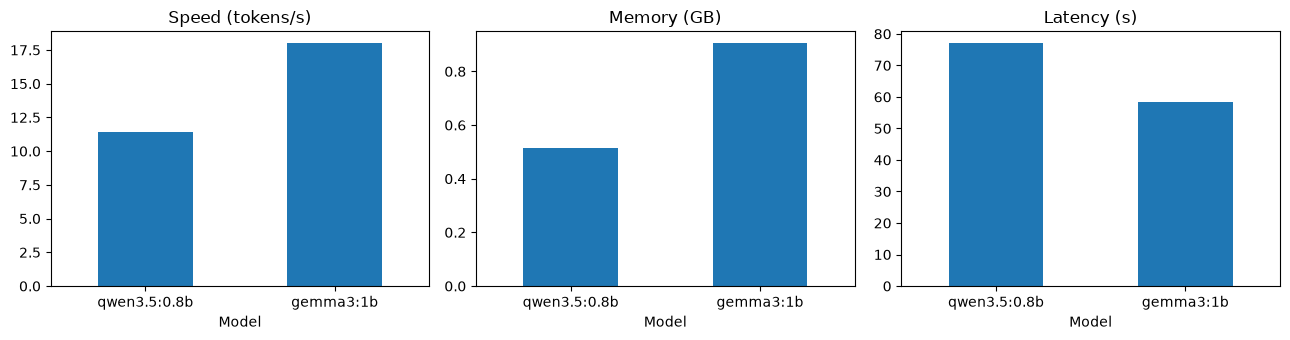

In [46]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 3, figsize=(13, 3.5))
bench_df.plot.bar(x="Model", y="Tokens/s", ax=ax[0], legend=False, title="Speed (tokens/s)", rot=0)
bench_df.plot.bar(x="Model", y="Loaded size (GB)", ax=ax[1], legend=False, title="Memory (GB)", rot=0)
bench_df.plot.bar(x="Model", y="Response time (s)", ax=ax[2], legend=False, title="Latency (s)", rot=0)
plt.tight_layout(); plt.show()

### Discussion — the model-size trade-off
```
Model size ──► Quality
           ──► Memory
           ──► Latency
           ──► Hardware requirements
```
Local model selection should be based on **actual measurements on the target machine**, not just public benchmark rankings.

**✍️ Your discussion:**

The benchmark shows that **Gemma3:1b performs better in speed and latency**, generating 17.98 tokens/s compared to 11.41 tokens/s for Qwen3.5:0.8b. Gemma3 also responds faster (58.46s vs. 76.96s).

However, Gemma3 has a larger loaded memory size (0.90 GB vs. 0.51 GB). Interestingly, Qwen uses more GPU memory in our earlier measurements, showing that memory consumption depends on model architecture and runtime configuration.

In our previous coding experiment, Gemma3 also produced more accurate code. Therefore, **Gemma3:1b is my preferred model** for local programming assistance, despite its higher loaded memory requirements.

Overall, larger models are not necessarily better. Model selection should consider accuracy, speed, memory consumption, and available hardware.

## Part 17 — Final Mini Project: **FSTT Local AI Assistant**

**Functional requirements:** runs entirely locally · uses Ollama + a local LLM · web interface · answers questions about a supplied course · uses local documents as knowledge · maintains conversation history · structured responses for selected questions · displays the answer · records response time.

```
Browser → Flask/Python ─┬─ Conversation history ─┐
                        └─ Documents → Retriever ┴─► Ollama → Local LLM
```

We reuse `rag.py` and create the final deliverable layout:
```
LocalAI_Lab/
├── source/ (app.py, chatbot.py, rag.py, benchmark.py, templates/)
├── documents/
├── screenshots/
├── report.pdf
└── README.md
```

In [7]:
import os
import shutil
from pathlib import Path

# Project root (parent of notebooks/)
ROOT = Path.cwd().parent

# Final deliverable folder
base = ROOT / "LocalAI_Lab"

# Create required folders
for d in ("source/templates", "documents", "screenshots"):
    (base / d).mkdir(parents=True, exist_ok=True)

# Copy Python files
shutil.copy(ROOT / "local_ai_lab/rag.py", base / "source/rag.py")
shutil.copy(ROOT / "local_ai_lab/benchmark.py", base / "source/benchmark.py")
shutil.copy(ROOT / "local-ai-web/app.py", base / "source/app.py")

# Copy HTML templates
for file in (ROOT / "local-ai-web/templates").glob("*.html"):
    shutil.copy(file, base / "source/templates" / file.name)

# Copy documents
for file in (ROOT / "documents").glob("*.txt"):
    shutil.copy(file, base / "documents" / file.name)

# Copy screenshots if available
for file in (ROOT / "screenshots").glob("*"):
    if file.is_file():
        shutil.copy(file, base / "screenshots" / file.name)

print("Final project created at:", base)
print("Contents:", sorted(os.listdir(base)))

Final project created at: /home/passenger/Desktop/LocalAI_Lab/LocalAI_Lab
Contents: ['documents', 'screenshots', 'source']


In [ ]:
%%writefile LocalAI_Lab/source/chatbot.py
"""Console chatbot with conversation memory (uses /api/chat)."""
import requests

OLLAMA = "http://localhost:11434"
MODEL = "qwen3.5"


def main():
    messages = [{"role": "system", "content": "You are a helpful, concise assistant."}]
    print("Local AI Assistant — type 'exit' to stop.")
    while True:
        q = input("\nYou: ")
        if q.lower() == "exit":
            break
        messages.append({"role": "user", "content": q})
        r = requests.post(f"{OLLAMA}/api/chat",
                          json={"model": MODEL, "messages": messages, "stream": False})
        r.raise_for_status()
        reply = r.json()["message"]
        messages.append({"role": "assistant", "content": reply["content"]})
        print("\nAI:", reply["content"])


if __name__ == "__main__":
    main()

Writing ../LocalAI_Lab/source/chatbot.py


In [ ]:
%%writefile LocalAI_Lab/source/app.py
"""FSTT Local AI Assistant — Flask + Ollama + local RAG + conversation history."""
import json, os, time
import requests
from flask import Flask, jsonify, render_template, request

import rag

OLLAMA = os.environ.get("OLLAMA_URL", "http://localhost:11434")
MODEL = os.environ.get("MODEL", "qwen3.5")
DOC_DIR = os.path.join(os.path.dirname(__file__), "..", "documents")
MAX_TURNS = 6                      # remembered user/assistant pairs

app = Flask(__name__)
retriever = rag.Retriever(rag.load_documents(DOC_DIR))
history = []                       # [{"role": ..., "content": ...}]  (single-user demo)

SYSTEM = ("You are the FSTT Local AI Assistant. Answer questions about the course using only the "
          "provided CONTEXT. If the answer is not in the context, say: \"Information not available.\" "
          "Be concise.")

# Structured response schema used for "Analyze ..." / "Quiz ..." style questions
STRUCT_SCHEMA = {
    "type": "object",
    "properties": {
        "topic": {"type": "string"},
        "summary": {"type": "string"},
        "key_points": {"type": "array", "items": {"type": "string"}},
        "difficulty": {"type": "string", "enum": ["easy", "medium", "hard"]},
    },
    "required": ["topic", "summary", "key_points", "difficulty"],
}


def call_ollama(messages, structured=False):
    payload = {"model": MODEL, "messages": messages, "stream": False, "think": False}
    if structured:
        payload["format"] = STRUCT_SCHEMA
    r = requests.post(f"{OLLAMA}/api/chat", json=payload, timeout=600)
    r.raise_for_status()
    return r.json()


@app.route("/")
def index():
    return render_template("index.html", model=MODEL, docs=list(retriever.docs))


@app.route("/ask", methods=["POST"])
def ask():
    body = request.get_json(force=True)
    question = (body.get("question") or "").strip()
    structured = bool(body.get("structured"))
    if not question:
        return jsonify(error="Empty question"), 400

    hits, context = retriever.context(question, k=2)
    user_msg = f"CONTEXT:\n{context or '(none)'}\n\nQUESTION: {question}"
    messages = [{"role": "system", "content": SYSTEM}] + history[-2 * MAX_TURNS:] \
               + [{"role": "user", "content": user_msg}]

    t0 = time.perf_counter()
    try:
        out = call_ollama(messages, structured)
    except requests.RequestException as e:
        return jsonify(error=f"Ollama error: {e}"), 502
    elapsed = time.perf_counter() - t0

    answer = out["message"]["content"]
    # store the plain question (not the long context) to keep history small
    history.append({"role": "user", "content": question})
    history.append({"role": "assistant", "content": answer})

    parsed = None
    if structured:
        try:
            parsed = json.loads(answer)
        except json.JSONDecodeError:
            pass

    tokens = out.get("eval_count")
    tps = tokens / (out["eval_duration"] / 1e9) if tokens and out.get("eval_duration") else None
    return jsonify(answer=answer, structured=parsed,
                   sources=[{"doc": n, "score": round(s, 2)} for n, s in hits],
                   seconds=round(elapsed, 2), tokens=tokens,
                   tokens_per_s=round(tps, 1) if tps else None)


@app.route("/reset", methods=["POST"])
def reset():
    history.clear()
    return jsonify(ok=True)


if __name__ == "__main__":
    # Bind to localhost ONLY (see report question Q15 on security)
    app.run(host="127.0.0.1", port=int(os.environ.get("PORT", 5001)), debug=False)

Overwriting ../LocalAI_Lab/source/app.py


In [ ]:
%%writefile LocalAI_Lab/source/templates/index.html
<!DOCTYPE html>
<html lang="en">
<head>
<meta charset="utf-8">
<title>FSTT Local AI Assistant</title>
<style>
  body { font-family: system-ui, sans-serif; max-width: 820px; margin: 2rem auto; padding: 0 1rem; color:#222; }
  h1 { margin-bottom: .2rem; } .sub { color:#666; font-size:.9rem; margin-bottom:1rem; }
  #chat { border:1px solid #ddd; border-radius:8px; padding:1rem; height:420px; overflow-y:auto; background:#fafafa; }
  .msg { margin:.6rem 0; padding:.6rem .8rem; border-radius:8px; white-space:pre-wrap; }
  .user { background:#e3f0ff; } .ai { background:#fff; border:1px solid #e5e5e5; }
  .meta { font-size:.75rem; color:#777; margin-top:.3rem; }
  form { display:flex; gap:.5rem; margin-top:1rem; } input[type=text] { flex:1; padding:.6rem; }
  button { padding:.6rem 1rem; cursor:pointer; } label { font-size:.85rem; }
</style>
</head>
<body>
<h1>🎓 FSTT Local AI Assistant</h1>
<div class="sub">Model: <b>{{ model }}</b> · Documents: {{ docs|join(", ") }} · Runs 100% locally</div>
<div id="chat"></div>
<form id="f">
  <input type="text" id="q" placeholder="Ask a question about the course..." autocomplete="off" autofocus>
  <button type="submit">Ask</button>
  <button type="button" id="reset">Reset</button>
</form>
<label><input type="checkbox" id="struct"> Structured response (JSON)</label>

<script>
const chat = document.getElementById("chat");
function add(cls, text, meta) {
  const d = document.createElement("div"); d.className = "msg " + cls; d.textContent = text;
  if (meta) { const m = document.createElement("div"); m.className = "meta"; m.textContent = meta; d.appendChild(m); }
  chat.appendChild(d); chat.scrollTop = chat.scrollHeight; return d;
}
document.getElementById("f").onsubmit = async (e) => {
  e.preventDefault();
  const q = document.getElementById("q"); const question = q.value.trim(); if (!question) return;
  q.value = ""; add("user", question);
  const wait = add("ai", "…thinking…");
  try {
    const r = await fetch("/ask", {method:"POST", headers:{"Content-Type":"application/json"},
      body: JSON.stringify({question, structured: document.getElementById("struct").checked})});
    const j = await r.json(); wait.remove();
    if (j.error) { add("ai", "⚠️ " + j.error); return; }
    const text = j.structured ? JSON.stringify(j.structured, null, 2) : j.answer;
    const src = j.sources.map(s => s.doc).join(", ") || "none";
    add("ai", text, `⏱ ${j.seconds}s · ${j.tokens ?? "?"} tokens · ${j.tokens_per_s ?? "?"} tok/s · sources: ${src}`);
  } catch (err) { wait.remove(); add("ai", "⚠️ " + err); }
};
document.getElementById("reset").onclick = async () => { await fetch("/reset", {method:"POST"}); chat.innerHTML = ""; };
</script>
</body>
</html>

Overwriting ../LocalAI_Lab/source/templates/index.html


In [ ]:
%%writefile LocalAI_Lab/README.md
# FSTT Local AI Assistant

A fully local assistant: Flask web UI → Ollama → local LLM, with a keyword (TF-IDF) retriever over `documents/`,
conversation history, structured (JSON) answers and response-time display.

## Setup
```bash
ollama pull qwen3.5
pip install flask requests psutil pandas
```

## Run
```bash
cd source
python app.py            # http://127.0.0.1:5001
python chatbot.py        # console chatbot
python benchmark.py qwen3.5 gemma3
```
Environment variables: `MODEL`, `OLLAMA_URL`, `PORT`.

Writing ../LocalAI_Lab/README.md


**Test the final app from the notebook:** launch it as a background process, send a few questions, then stop it.

In [14]:
import subprocess, sys, time

env = {**os.environ, "MODEL": MODEL, "PORT": "5001"}
server = subprocess.Popen([sys.executable, "app.py"], cwd="../LocalAI_Lab/source", env=env,
                          stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)
time.sleep(3)

def app_ask(q, structured=False):
    r = requests.post("http://127.0.0.1:5001/ask", json={"question": q, "structured": structured}, timeout=600)
    return r.json()

try:
    for q, s in [("What is reinforcement learning?", False),
                 ("And how is it different from supervised learning?", False),   # tests history
                 ("Summarize deep learning", True),                              # structured
                 ("What is quantum computing?", False)]:                         # not in the docs
        j = app_ask(q, s)
        print(f"Q: {q}\nA: {j.get('structured') or j.get('answer') or j}\n"
              f"   sources={j.get('sources')} · {j.get('seconds')}s · {j.get('tokens_per_s')} tok/s\n")
finally:
    pass  # keep running so you can open http://127.0.0.1:5001 — stop in the next cell

Q: What is reinforcement learning?
A: Reinforcement learning is a branch of artificial intelligence where an agent learns to make decisions by interacting with an environment through experiences, utilizing rewards or penalties to guide its actions and policies.
   sources=[{'doc': 'course.txt', 'score': 1.08}, {'doc': 'reinforcement_learning.txt', 'score': 1.02}] · 18.41s · 12.3 tok/s

Q: And how is it different from supervised learning?
A: Reinforcement learning differs from supervised learning in that reinforcement learning uses agents (actors) and rewards/penalities to make decisions within an environment, unlike supervised learning which maps input features directly to outputs using labelled data for classification or regression.
   sources=[{'doc': 'course.txt', 'score': 1.08}, {'doc': 'machine_learning.txt', 'score': 1.06}] · 5.12s · 12.4 tok/s

Q: Summarize deep learning
A: {'difficulty': 'hard', 'key_points': ['Uses many layers', 'Enables representation learning from datasets']

In [15]:
server.terminate(); server.wait(timeout=10)
print("Server stopped.")

Server stopped.


> 📸 Open <http://127.0.0.1:5001> in your browser while the server is running and take your screenshots: `01_installation.png`, `02_model.png`, `03_chatbot.png`, `04_python.png`, `05_rag.png`, `06_webapp.png`.

## Part 18 — Questions for the Report
Answer each question in your own words (use your measurements from Parts 6 and 16 for Q13–Q14).

**Q1.** What is Local AI?

- Local AI refers to artificial intelligence models that run directly on a personal computer or local server instead of relying on cloud services. It uses local hardware (CPU, GPU, and RAM) to perform inference.

**Q2.** Difference between a Cloud LLM and a Local LLM?

- A Cloud LLM runs on remote servers and usually requires an internet connection, while a Local LLM runs directly on the user's computer and can work offline once installed.

**Q3.** What role does Ollama play?

- Ollama allows users to download, manage, and run LLMs locally. It also provides a REST API that enables Python applications to communicate with these models.

**Q4.** What is model quantization?

- Model quantization reduces the numerical precision of model weights, for example, from 32-bit to 8-bit or 4-bit. This reduces memory consumption and can improve inference efficiency, although it may slightly affect model accuracy.

**Q5.** Why does model size affect memory consumption?

- Larger models generally have more parameters that require memory for storage and processing. However, actual memory usage also depends on quantization, architecture, context length, and runtime configuration.

**Q6.** Why can a smaller model sometimes be preferable?

- Smaller models usually require fewer computational resources, consume less memory, and can provide faster responses. They are particularly suitable for simple tasks and computers with limited hardware.

**Q7.** Advantages of local inference?

- Local inference improves data privacy, supports offline operation, provides greater control over models, and avoids per-request cloud API costs.

**Q8.** Disadvantages of local inference?

- Local inference depends on available hardware resources. Limited RAM or GPU memory can reduce performance, smaller models may produce less accurate results, and users must manage installation and maintenance themselves.

**Q9.** Explain the architecture of your Python application.

- My application uses Flask to provide a web interface. Python manages conversation history and retrieves relevant information from local documents using a retriever. The question and context are sent to Ollama through its REST API, and the local LLM generates a response displayed in the browser with the response time. The application also supports structured JSON responses.

**Architecture:**

`Browser → Flask → Conversation History + RAG → Ollama → Local LLM → Response`

**Q10.** Explain the role of the REST API.

- The REST API allows the Python application to communicate with Ollama using HTTP requests. Python sends prompts in JSON format, and Ollama returns the generated responses.

**Q11.** What is RAG?

- Retrieval-Augmented Generation (RAG) combines document retrieval with text generation. It retrieves relevant information from documents and provides it to the LLM as context, helping the model generate answers based on specific sources.

**Q12.** Difference between an LLM and a multimodal LLM?

- A traditional text-based LLM processes and generates text, while a multimodal LLM can process multiple types of data, such as text and images. For example, I used Qwen3.5:0.8b to analyze an image of a cat.

**Q13.** Compare two local models experimentally.

- I compared **Qwen3.5:0.8b** and **Gemma3:1b** using Ollama on my NVIDIA GeForce MX350 GPU with 2 GB VRAM.

| Metric | Qwen3.5:0.8b | Gemma3:1b |
|---|---:|---:|
| Disk size (GB) | 1.32 | 0.81 |
| Loaded size (GB) | 0.51 | 0.90 |
| Reported VRAM (GB) | 0.51 | 0.07 |
| Load time (s) | 14.17 | 14.64 |
| Response time (s) | 76.96 | **58.46** |
| Generated tokens | 706 | 782 |
| Generation speed (tokens/s) | 11.41 | **17.98** |
| System RAM usage (%) | 71.3 | 79.2 |

- **Gemma3:1b performed better in speed**, generating 17.98 tokens/s compared to 11.41 tokens/s for Qwen3.5:0.8b. It also responded faster (58.46s vs. 76.96s).
- **Qwen3.5:0.8b had a smaller loaded memory size** (0.51 GB vs. 0.90 GB).
- In the previous coding experiment, Gemma3 generated more accurate Python code and passed all 2,005 test cases, while Qwen3.5 failed one case.
- Overall, Gemma3 performed better in speed and code correctness in my experiments, although the reported VRAM values indicate that the models may have used different CPU/GPU memory allocations during benchmarking.

**Q14.** Which model would you deploy on a computer with limited RAM? Explain.

- I would choose **Qwen3.5:0.8b** if minimizing loaded memory consumption is the priority, because it required approximately 0.51 GB compared to 0.90 GB for Gemma3:1b in my benchmark. However, if sufficient memory is available, I would prefer Gemma3:1b because it provided faster responses and better coding results.

**Q15.** What security risks exist when exposing a local LLM server to a network?

- Exposing a local LLM server can allow unauthorized users to access the API, consume computing resources, or potentially access sensitive information.
- Ollama does not provide authentication by default, and configuring `OLLAMA_HOST=0.0.0.0` makes the server listen on all network interfaces.
- Other risks include prompt injection through untrusted documents and potential exposure of application data.
- To improve security, I would restrict access using firewall rules, keep Ollama accessible through `localhost` when possible, and use a reverse proxy with authentication and HTTPS/TLS for remote access.

## Part 19 — Deliverables
Final check of the submission folder:
```
LocalAI_Lab/
├── report.pdf
├── source/        app.py · chatbot.py · rag.py · benchmark.py
├── documents/     ai.txt · ml.txt · rl.txt  (+ the other course files)
├── screenshots/   01_installation.png … 06_webapp.png
└── README.md
```

In [ ]:
required = [
    "LocalAI_Lab/report.pdf",
    "LocalAI_Lab/README.md",
    "LocalAI_Lab/source/app.py", "LocalAI_Lab/source/chatbot.py",
    "LocalAI_Lab/source/rag.py", "LocalAI_Lab/source/benchmark.py",
    "LocalAI_Lab/screenshots/01_installation.png", "LocalAI_Lab/screenshots/02_model.png",
    "LocalAI_Lab/screenshots/03_chatbot.png", "LocalAI_Lab/screenshots/04_python.png",
    "LocalAI_Lab/screenshots/05_rag.png", "LocalAI_Lab/screenshots/06_webapp.png",
]
for p in required:
    print("✅" if os.path.exists(p) else "⬜ missing", p)
print("\nDocuments:", sorted(os.listdir("../LocalAI_Lab/documents")))

✅ report.pdf
✅ README.md
✅ source/app.py
✅ source/chatbot.py
✅ source/rag.py
✅ source/benchmark.py
✅ screenshots/01_installation.png
✅ screenshots/02_model.png
✅ screenshots/03_chatbot.png
✅ screenshots/04_python.png
✅ screenshots/05_rag.png
✅ screenshots/06_webapp.png

Documents: ['ai.txt', 'course.txt', 'deep_learning.txt', 'machine_learning.txt', 'reinforcement_learning.txt']
